# Data Ingestion

### Executive Summary

This notebook documents the initial research and benchmarking of raw data streams for grid telemetry, weather forecasts, and weather observations

### Key Deicisions
1. **Grid Telemetry Source** Evaluated raw ISO-NE API endpoints versus the 'gridstatus' library/service. Confrimed that both return identical 5-minute telemetry. 
2. **Weather Forecasts**: Initially tested GRIB2 file downloads via the `Herbie` library. Found that it took ~ 45 minutes per year. Switched to AWS S3 Zarr source `s3://hrrrzrr/` which brought it down to ~ 7 minutes per year
3. **Weather Obserservations**: Used Open-Meteo Archive API for historical hourly observatios across 4 New England s: Boston (BOS): Popolation/Demand center, Worcester (ORH): Solar Generation hub, Hartford (BDL): Population and Solar Hub ,Bangor (BGR): Wind Generation Hub.
4. **Function Refactoring**: Logic was taken from exploration work here and put into modular scripts:
   - `src/data/grid_loader.py`: ISO-NE telemetry extraction
   - `src/data/weather_loader.py`: HRRR Zarr forecast querying and Open-Meteo observation fetches.



In [1]:
import sys
print(f"Python Executable: {sys.executable}")
print(f"Python Version: {sys.version}")
%load_ext autoreload
%autoreload 2

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import gridstatus
from dotenv import load_dotenv
from gridstatus.isone_api import isone_api
import os
from gridstatusio import GridStatusClient
import time
from pathlib import Path
import sklearn as sk
import herbie
from herbie import Herbie
herbie.accessors.xr.set_options(use_new_combine_kwarg_defaults=True)
import xarray as xr
import fsspec
import pyarrow.parquet as pq
from pathlib import Path
from concurrent.futures import ThreadPoolExecutor, as_completed

import src.data.weather_loader as wl
import src.data.grid_loader as gl


load_dotenv()

Python Executable: c:\Users\evanh\Documents\Jupyter\energy-systems-analysis\.venv\Scripts\python.exe
Python Version: 3.12.3 (tags/v3.12.3:f6650f9, Apr  9 2024, 14:05:25) [MSC v.1938 64 bit (AMD64)]
There is a newer version of the gridstatusio library available (0.16.1). You are using version 0.16.0.

We recommend upgrading via the 'uv pip install --upgrade gridstatusio' command.

See the changelog here: https://github.com/gridstatus/gridstatusio/blob/main/CHANGELOG.md


True

## Grid Telemetry
The development work below is a mess and not worth the time currently to retroactively clean up

The ultimate conclusion was: The three different ways of Getting BTM Solar Esitmate (2 from the ISONE API, one from Gridstatus) all have the same value. (as seen in estimate_delta2. Estimate_Delta represents the diff between the two ISONE API methods). Given the need for historical data, Gridstatus was the only viable option 

#### ISO-NE API Raw Data

In [2]:
iso = isone_api.ISONEAPI()

In [3]:
ex = iso.get_total_demand('2025-03-01','2025-03-02')

In [4]:
ex['BTM_Solar_Estimate'] =  ex['Total Load With Estimated Solar'] - ex['Total Load']
ex['BTM Solar Native Estimate'] = ex['Native Load With Estimated Solar'] - ex['Native Load'] 

ex['Estimate_Delta'] = ex['BTM_Solar_Estimate'] - ex['BTM Solar Native Estimate']


<Axes: >

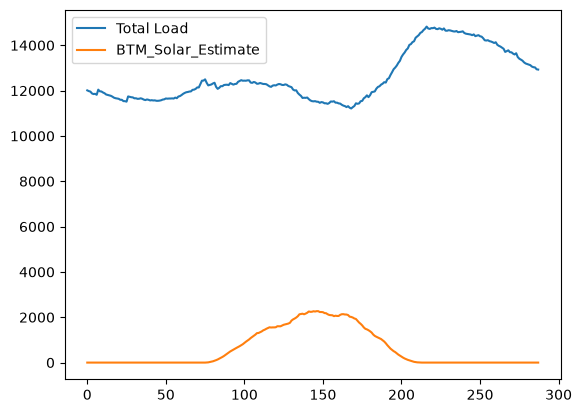

In [5]:
ex[['Total Load','BTM_Solar_Estimate']].plot()

In [6]:
gen_fuel_mix = iso.get_fuel_mix('2025-03-01','2025-03-02')
gen_fuel_mix.head()

,Time,Coal,Hydro,Landfill Gas,Natural Gas,Nuclear,Other,Refuse,Solar,Wind,Wood
0,2025-03-01 00:00:41-05:00,7.0,484.0,27.0,6161.0,3353.0,1.0,308.0,2.0,293.0,224.0
1,2025-03-01 00:01:51-05:00,8.0,488.0,27.0,6124.0,3349.0,29.0,309.0,2.0,295.0,224.0
2,2025-03-01 00:05:30-05:00,9.0,487.0,27.0,6115.0,3351.0,1.0,311.0,2.0,302.0,226.0
3,2025-03-01 00:07:46-05:00,9.0,488.0,27.0,6121.0,3349.0,1.0,310.0,2.0,301.0,227.0
4,2025-03-01 00:11:50-05:00,2.0,487.0,27.0,6144.0,3352.0,7.0,310.0,2.0,310.0,228.0


#### Gridstatus Processed Data

In [7]:
g_btm = gridstatus.ISONE().get_load(date = '2025-03-01', end = '2025-03-02')
solar_join = g_btm.join(ex, rsuffix = 'L_')
solar_join.head()

,Time,Interval Start,Interval End,Load,Interval StartL_,Interval EndL_,Total Load,Native Load,Storage Load,Total Load With Estimated Solar,Native Load With Estimated Solar,BTM_Solar_Estimate,BTM Solar Native Estimate,Estimate_Delta
0,2025-03-01 00:00:00-05:00,2025-03-01 00:00:00-05:00,2025-03-01 00:05:00-05:00,11997.706,2025-03-01 00:00:00-05:00,2025-03-01 00:05:00-05:00,12010.906,11997.706,13.2,12010.906,11997.706,0.0,0.0,0.0
1,2025-03-01 00:05:00-05:00,2025-03-01 00:05:00-05:00,2025-03-01 00:10:00-05:00,11962.362,2025-03-01 00:05:00-05:00,2025-03-01 00:10:00-05:00,11977.662,11962.362,15.3,11977.662,11962.362,0.0,0.0,0.0
2,2025-03-01 00:10:00-05:00,2025-03-01 00:10:00-05:00,2025-03-01 00:15:00-05:00,11911.466,2025-03-01 00:10:00-05:00,2025-03-01 00:15:00-05:00,11955.966,11911.466,44.5,11955.966,11911.466,0.0,0.0,0.0
3,2025-03-01 00:15:00-05:00,2025-03-01 00:15:00-05:00,2025-03-01 00:20:00-05:00,11861.933,2025-03-01 00:15:00-05:00,2025-03-01 00:20:00-05:00,11875.233,11861.933,13.3,11875.233,11861.933,0.0,0.0,0.0
4,2025-03-01 00:20:00-05:00,2025-03-01 00:20:00-05:00,2025-03-01 00:25:00-05:00,11825.631,2025-03-01 00:20:00-05:00,2025-03-01 00:25:00-05:00,11847.531,11825.631,21.9,11847.531,11825.631,0.0,0.0,0.0


The three different ways of Getting BTM Solar Esitmate (2 from the ISONE API, one from Gridstatus) all have the same value.

Fetch Telemetry Function moved to `grid_loader.py`

In [8]:
df = gl.fetch_telemetry("2026-01-01","2026-12-31")

fetching data for 2026...


<Axes: xlabel='interval_start_utc'>

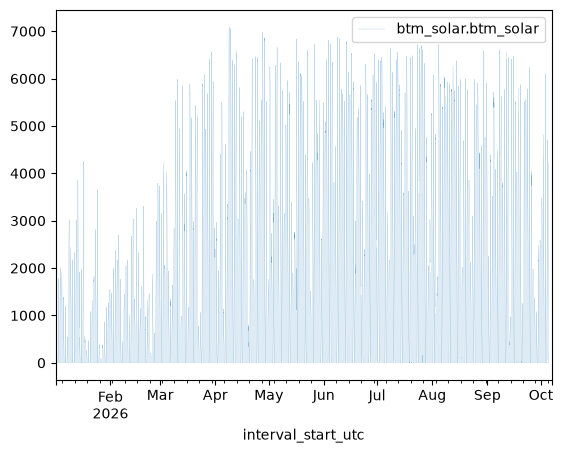

In [9]:
df[["interval_start_utc", "btm_solar.btm_solar"]].plot(kind = 'line', lw = 0.1, x = 'interval_start_utc', y = 'btm_solar.btm_solar')

BTM Solar Estimates are available starting 2020-12-01. For Simplicity I'll Include 2021- 2025 for Training/Testing and then use 2026 for Validation

## Capacity/Unbiasing Data

### Data Processing & Analysis

The code below explores taking hourly solar generation data and inferring what the total installed capacity is. To get a sense of the distribution of inferred capacity, I plot several quantiles across time and regions

In [10]:
btm_raw = pd.read_excel("data/raw/btm_pv_data.xlsx", sheet_name = 1)
btm_norm = pd.read_excel("data/raw/btm_pv_data.xlsx", sheet_name = 2)

In [11]:
btm_raw = pd.melt(btm_raw,id_vars=['Year','Month','Day','HourEnding'],var_name='zone',value_name = 'btm_raw')
btm_raw = btm_raw[btm_raw['Year'] >= 2021]

btm_norm= pd.melt(btm_norm,id_vars=['Year','Month','Day','HourEnding'],var_name='zone',value_name='btm_norm')


In [12]:
hourly_solar_gen = btm_raw.merge(btm_norm, how = 'inner',on = ['Year','Month','Day','HourEnding','zone'],
    suffixes= [None,"_norm"]) 
    
hourly_solar_gen = hourly_solar_gen[hourly_solar_gen['btm_norm']>0.50]
hourly_solar_gen['inferred_capacity_mw'] = hourly_solar_gen['btm_raw'] / hourly_solar_gen['btm_norm']
hourly_solar_gen.head()

,Year,Month,Day,HourEnding,zone,btm_raw,btm_norm,inferred_capacity_mw
155,2021,1,7,12,CT,284.0,0.502,565.737052
179,2021,1,8,12,CT,295.7,0.522,566.475096
180,2021,1,8,13,CT,290.0,0.511,567.514677
203,2021,1,9,12,CT,298.5,0.530,563.207547
204,2021,1,9,13,CT,292.8,0.520,563.076923


In [13]:
monthly_capacity_quantiles = hourly_solar_gen.groupby(['Year','Month','zone'])['inferred_capacity_mw'].quantile([0.25,0.5,0.75,0.99]).reset_index()
monthly_capacity_quantiles  = monthly_capacity_quantiles.rename({'level_3':'quantile'},axis = 1)
monthly_capacity_quantiles.head()

,Year,Month,zone,quantile,inferred_capacity_mw
0,2021,1,CT,0.25,566.342542
1,2021,1,CT,0.50,568.269231
2,2021,1,CT,0.75,570.912668
3,2021,1,CT,0.99,571.766989
4,2021,1,ISONE,0.25,2019.901777


### Inferred Capacity Visualizations

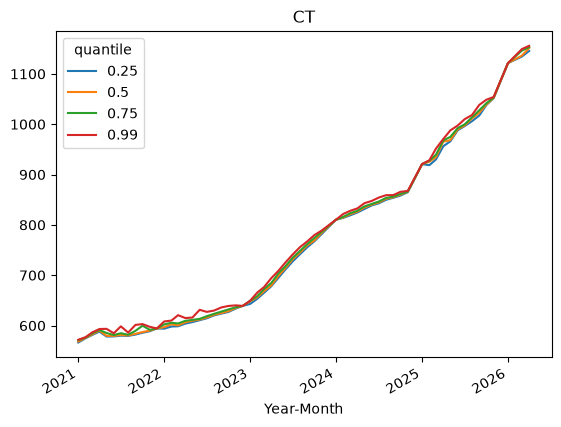

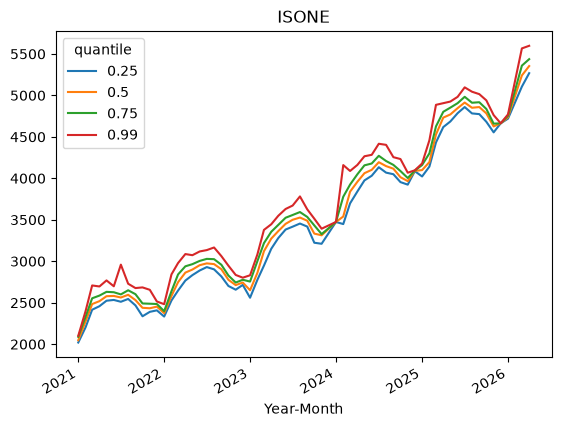

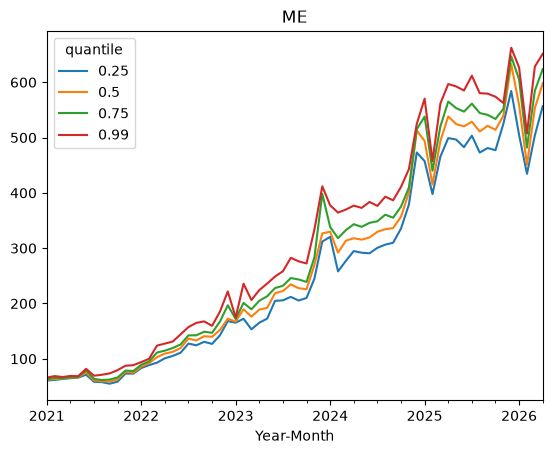

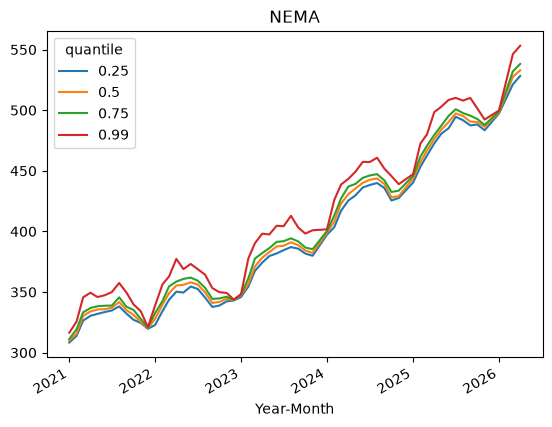

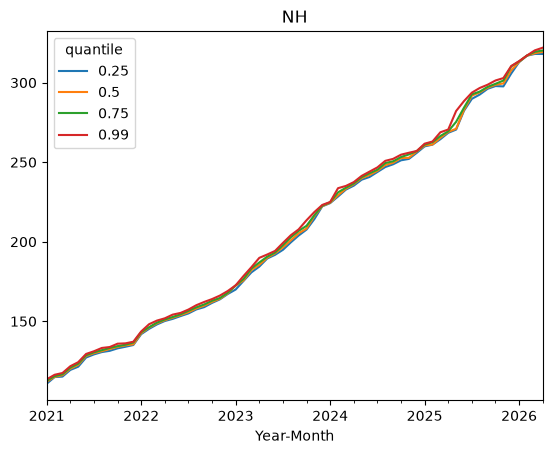

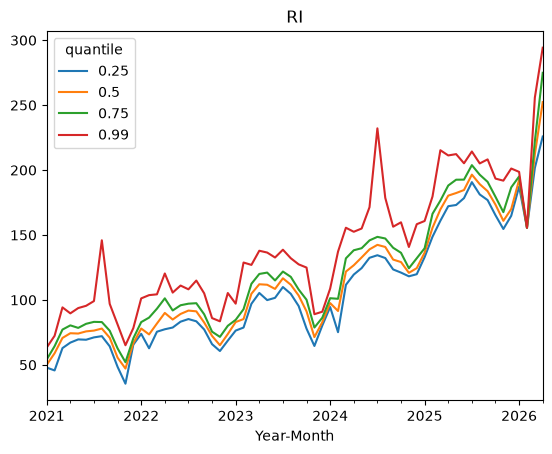

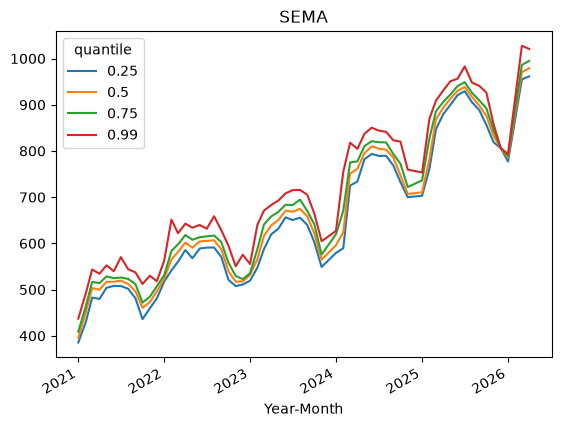

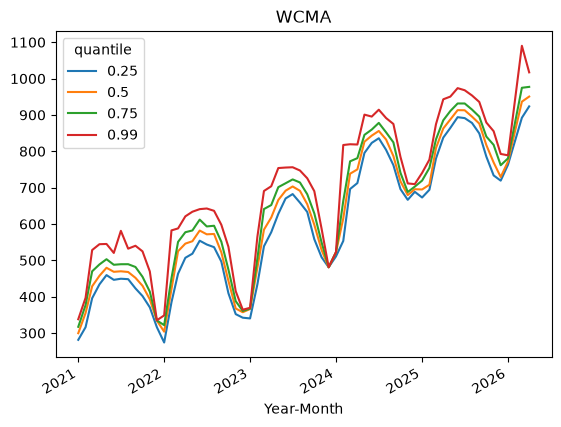

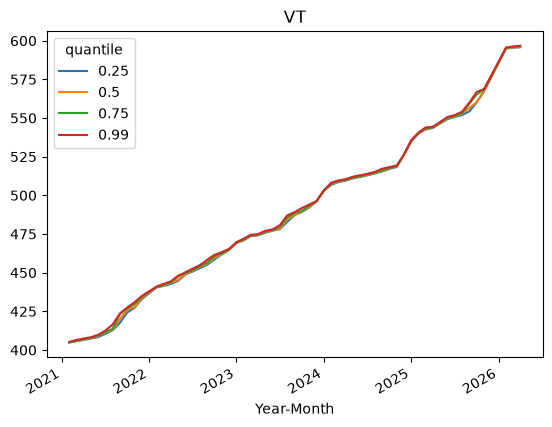

In [14]:
for x in monthly_capacity_quantiles['zone'].unique():
    monthly_capacity_quantiles['Year-Month'] = pd.to_datetime(monthly_capacity_quantiles['Year'].astype(str) +'-' +monthly_capacity_quantiles['Month'].astype(str))
    monthly_capacity_quantiles[monthly_capacity_quantiles['zone'] == x].pivot(index = 'Year-Month',columns='quantile',
                        values='inferred_capacity_mw').plot(kind = 'line',title = x)



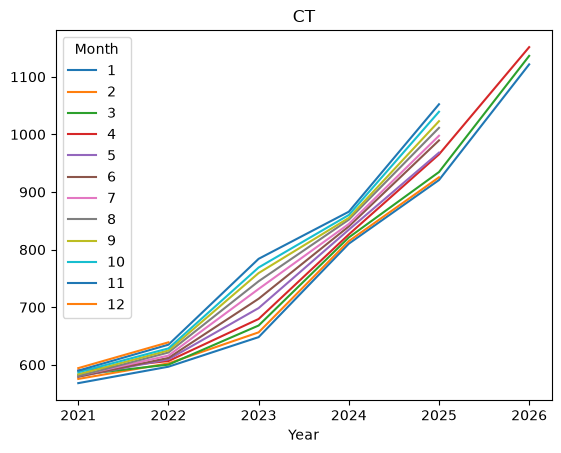

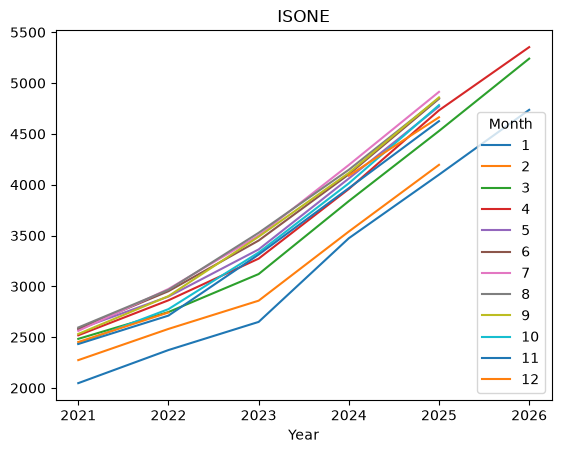

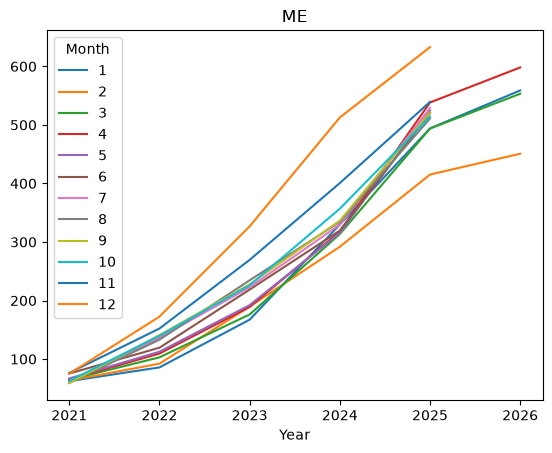

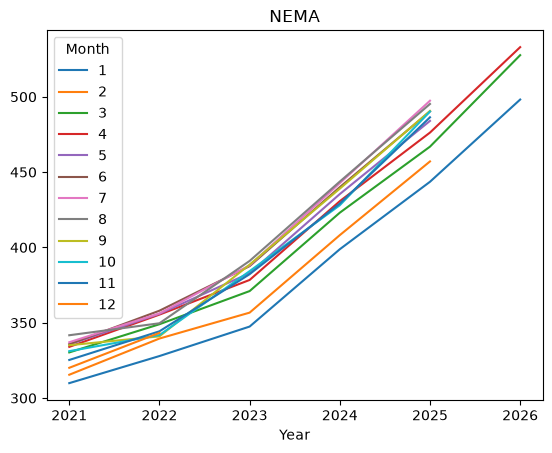

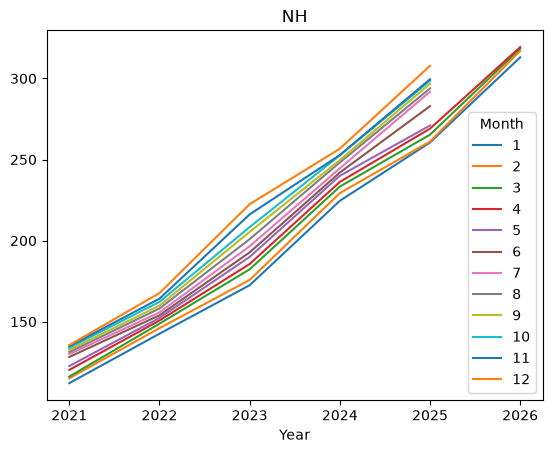

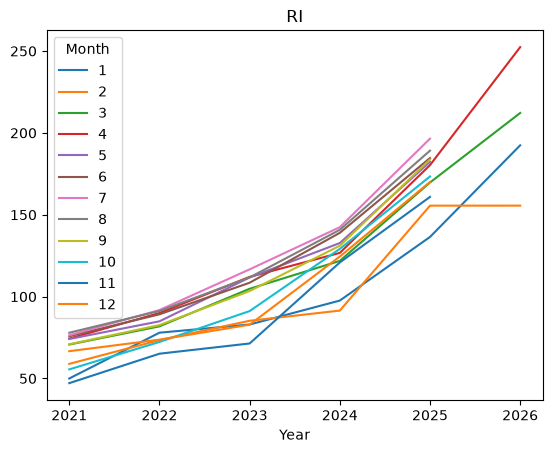

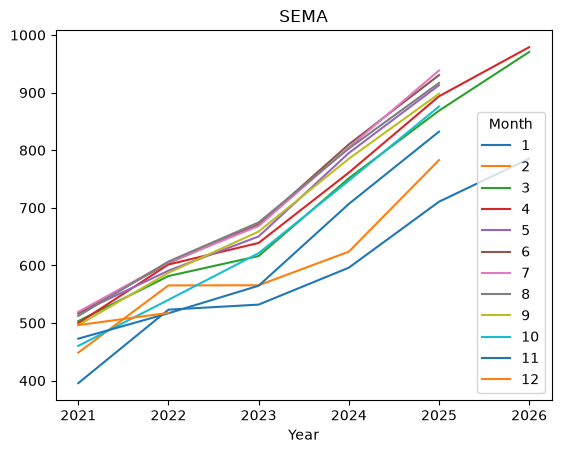

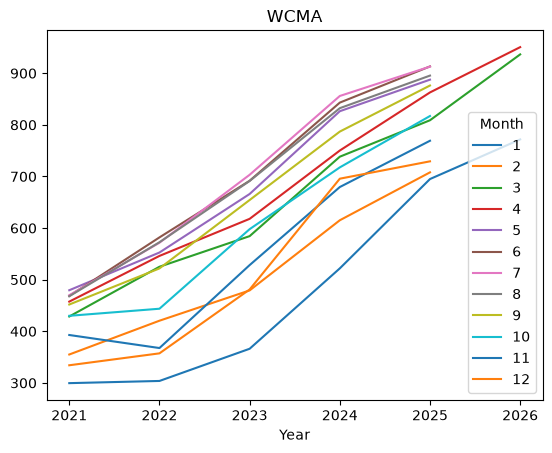

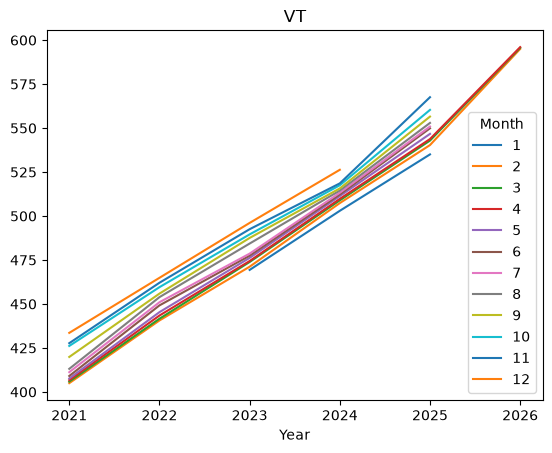

In [15]:
for x in monthly_capacity_quantiles['zone'].unique():
    monthly_capacity_quantiles['Year-Month'] = pd.to_datetime(monthly_capacity_quantiles['Year'].astype(str) +'-' +monthly_capacity_quantiles['Month'].astype(str))
    monthly_capacity_quantiles[(monthly_capacity_quantiles['zone'] == x)& (monthly_capacity_quantiles['quantile'] == 0.5) ].pivot(index = 'Year',columns='Month',
                        values='inferred_capacity_mw').plot(kind = 'line',title = x)



### BTM Capacity Analysis

The data above suggests a few things. 
1. False Seasonality: For several of the zones, we see a winter dip in inferred BTM generation capacity. This value is supposed to represent actual hardware thats installed and panels are removed so infrequently that this should essentially be monotonically increasing. There are several explanation that are likely partially responsible:

    1. Extremely small population of hours in winter months where BTM solar is producing at a meaningful rate, leading to noisier data points
    2. Massachusetts BTM panels have a high proportion of roof mounted installations which are gnerally at a lower angle (18 - 26 degrees) vs ground mounted systems (30-35 degrees) 
2) Estimates Close to CELT: ISO-NE publishes a yearly CELT report which includes the results of surveys aimed at estimating BTM solar capacity. The yearly max of inferred calculations above are very close to those published ground-truths. 

Given that, BTM Generation will be normalized by linearly interpolating the yearly CELT Survey data to the month level

# Weather Data

## Forecast Data

#### Herbie Library

Conclusion from this exploration was that this method was incredible inefficient. For every measurement level (surface, 2m, each atmospheric level) I would have to download the entire forecast before filtering it down to the centroids of interest. 

In [16]:
from herbie import Herbie

In [17]:
# Create a Herbie object for HRRR model data
H = Herbie(
    '2021-01-01 08:00',  # Date and time
    model='hrrr',         # Model name
    product='sfc',        # Product type
    fxx=1                 # Forecast hour
)

# Show file contents
H.inventory()


ds_2m = H.xarray(":(TMP|DPT):2 m above ground:")
ds_sfc = H.xarray(":DSWRF:surface:")

✅ Found ┊ model=hrrr ┊ product=sfc ┊ 2021-Jan-01 08:00 UTC F01 ┊ GRIB2 @ aws ┊ IDX @ local


In [18]:
#Starting with Boston-area, Worcester MA, Hartford CT, Bangor ME
points = pd.DataFrame({
    "latitude": [42.3601, 42.2626, 41.7658, 44.8016],
    "longitude": [-71.0589, -71.8023, -72.6734, -68.7712],
    'stid' : ['Boston','Worcester','Hartford','Bangor']
})
df_2m = ds_2m.herbie.pick_points(points).to_dataframe().set_index("point_stid")
df_sfc = ds_sfc.herbie.pick_points(points) .to_dataframe().set_index("point_stid")

In [19]:
forecast = pd.merge(df_2m,df_sfc,how='inner',on = 'point_stid')
forecast.reset_index()

,point_stid,t2m,d2m,time_x,step_x,heightAboveGround,latitude_x,longitude_x,valid_time_x,gribfile_projection_x,...,time_y,step_y,surface,latitude_y,longitude_y,valid_time_y,gribfile_projection_y,point_grid_distance_y,point_latitude_y,point_longitude_y
0,Boston,272.488892,268.941101,2021-01-01 08:00:00,0 days 01:00:00,2.0,42.365008,288.938949,2021-01-01 09:00:00,None,...,2021-01-01 08:00:00,0 days 01:00:00,0.0,42.365008,288.938949,2021-01-01 09:00:00,None,0.573655,42.3601,-71.0589
1,Worcester,268.926392,266.691101,2021-01-01 08:00:00,0 days 01:00:00,2.0,42.267862,288.218227,2021-01-01 09:00:00,None,...,2021-01-01 08:00:00,0 days 01:00:00,0.0,42.267862,288.218227,2021-01-01 09:00:00,None,1.787618,42.2626,-71.8023
2,Hartford,270.426392,268.816101,2021-01-01 08:00:00,0 days 01:00:00,2.0,41.758559,287.309823,2021-01-01 09:00:00,None,...,2021-01-01 08:00:00,0 days 01:00:00,0.0,41.758559,287.309823,2021-01-01 09:00:00,None,1.607647,41.7658,-72.6734
3,Bangor,268.738892,265.378601,2021-01-01 08:00:00,0 days 01:00:00,2.0,44.806769,291.223018,2021-01-01 09:00:00,None,...,2021-01-01 08:00:00,0 days 01:00:00,0.0,44.806769,291.223018,2021-01-01 09:00:00,None,0.733778,44.8016,-68.7712


In [22]:
SEARCH_ALL_VARIABLES = (
    ":(TMP|DPT):2 m above ground|"
    ":(UGRD|VGRD):10 m above ground|"
    ":(DSWRF|VBDSF|GUST):surface|"
    ":(LCDC|MCDC|HCDC):|"
    ":TCDC:entire atmosphere"
)
def extract_hour_all_in_one(H, points_df):
    """
    Downloads all 11 weather variables in 1 single network request per forecast hour
    and returns a clean, indexed DataFrame for the target centroids.
    """
    # 1 single network call to AWS S3!
    ds_list = H.xarray(SEARCH_ALL_VARIABLES)
    
    # Target columns to capture
    target_vars = ["t2m", "d2m", "u10", "v10", "gust", "sdswrf", "vbdsf", "lcc", "mcc", "hcc", "tcc"]
    
    # Initialize the container indexed by station name
    result = pd.DataFrame(index=points_df["stid"])
    
    # Loop over the datasets Herbie parsed from the single file
    for ds in ds_list:
        df_p = ds.herbie.pick_points(points_df, tree_name="hrrr").to_dataframe().set_index("point_stid")
        for col in df_p.columns:
            if col in target_vars:
                result[col] = df_p[col]
            elif col in ["time", "valid_time", "step"] and col not in result.columns:
                result[col] = df_p[col]
                
    # Compute total wind speed magnitude
    result["wind_speed_10m"] = np.sqrt(result["u10"]**2 + result["v10"]**2)
    
    return result.reset_index()


In [23]:
extract_hour_all_in_one(H,points)

Note: Returning a list of [7] xarray.Datasets because cfgrib opened with multiple hypercubes.


,stid,tcc,time,step,valid_time,u10,v10,t2m,d2m,hcc,lcc,mcc,gust,sdswrf,vbdsf,wind_speed_10m
0,Boston,0.0,2021-01-01 08:00:00,0 days 01:00:00,2021-01-01 09:00:00,2.631165,-1.279011,272.488892,268.941101,0.0,0.0,0.0,8.056046,0.0,0.0,2.925559
1,Worcester,0.0,2021-01-01 08:00:00,0 days 01:00:00,2021-01-01 09:00:00,2.006165,-0.716511,268.926392,266.691101,0.0,0.0,0.0,3.556046,0.0,0.0,2.130278
2,Hartford,0.0,2021-01-01 08:00:00,0 days 01:00:00,2021-01-01 09:00:00,0.818665,-1.904011,270.426392,268.816101,0.0,0.0,0.0,3.493546,0.0,0.0,2.072551
3,Bangor,0.0,2021-01-01 08:00:00,0 days 01:00:00,2021-01-01 09:00:00,1.631165,-0.654011,268.738892,265.378601,0.0,0.0,0.0,5.556046,0.0,0.0,1.757392


It looks like using Herbie to extract just 4 centroids is incredibly inefficient as it has to first download the entire hypercube before filtering. Back of the napkin math says downlading 5 years would take ~25-30 hours. 
I'll now explore using Zarr to extract the same datapoints in a more targeted way. That should hopefully speed things up dramatically

### Zarr HRRR Approach

In [24]:

# Static (y, x) grid pixels for the 4 centroids
STATION_COORDS = {
    "Boston": (776, 1615),
    "Worcester": (767, 1596),
    "Hartford": (742, 1578),
    "Bangor": (881, 1647),
}

url = "s3://hrrrzarr/sfc/20240601/20240601_16z_fcst.zarr/2m_above_ground/TMP/2m_above_ground"
ds = xr.open_zarr(fsspec.get_mapper(url, anon=True))


results = {}
for name, (y, x) in STATION_COORDS.items():
    results[name] = ds["TMP"][:9, y, x].values


df_temp = pd.DataFrame(results)
df_temp.index = [f"f{i+1:02d}" for i in range(9)]
df_temp


,Boston,Worcester,Hartford,Bangor
f01,298.791382,298.541382,300.666382,295.166382
f02,299.286865,298.849365,301.224365,295.411865
f03,299.858307,299.170807,301.545807,295.545807
f04,299.876068,299.313568,301.313568,295.313568
f05,299.864685,299.177185,300.802185,294.552185
f06,299.411316,298.786316,300.536316,293.723816
f07,298.466980,297.966980,299.966980,292.591980
f08,295.629852,296.567352,298.567352,290.254852
f09,290.107849,293.920349,296.232849,286.045349


In [26]:
zarr_1day = wl.fetch_single_day_zarr("2025-01-15")
zarr_1day.head()

,forecast_date,init_time_utc,lead_hour,valid_time_utc,valid_time_local,point_stid,dswrf,vbdsf,tmp_2m,dpt_2m,ugrd_10m,vgrd_10m,gust,tcdc,lcdc,mcdc,hcdc
0,2025-01-15,2025-01-15 17:00:00+00:00,1,2025-01-15 18:00:00+00:00,2025-01-15 13:00:00-05:00,BOS,456.200012,912.0,271.438843,258.934021,5.730122,-3.090336,10.125992,4.0,4.0,0.0,0.0
1,2025-01-15,2025-01-15 17:00:00+00:00,1,2025-01-15 18:00:00+00:00,2025-01-15 13:00:00-05:00,ORH,465.100006,934.0,270.251343,258.059021,5.167622,-3.402836,10.125992,1.0,1.0,0.0,0.0
2,2025-01-15,2025-01-15 17:00:00+00:00,1,2025-01-15 18:00:00+00:00,2025-01-15 13:00:00-05:00,BDL,476.600006,929.0,271.813843,257.184021,5.230122,-3.402836,10.000992,4.0,4.0,0.0,0.0
3,2025-01-15,2025-01-15 17:00:00+00:00,1,2025-01-15 18:00:00+00:00,2025-01-15 13:00:00-05:00,BGR,390.000000,774.0,268.813843,261.371521,4.480122,-2.965336,8.500992,31.0,31.0,0.0,0.0
4,2025-01-15,2025-01-15 17:00:00+00:00,2,2025-01-15 19:00:00+00:00,2025-01-15 14:00:00-05:00,BOS,364.899994,868.0,271.488647,258.825500,5.105417,-2.880558,8.994723,3.0,3.0,0.0,0.0


In [ ]:
wl.download_historical_forecasts(2021,2021)

In [29]:
wl.download_historical_forecasts(2026,2026)

[2026] Downloading 365 remaining days out of 365...
  [1/365] Processed 2026-01-01
  [2/365] Processed 2026-01-02
  [3/365] Processed 2026-01-03
  [4/365] Processed 2026-01-04
  [5/365] Processed 2026-01-05
  [6/365] Processed 2026-01-06
  [7/365] Processed 2026-01-07
  [8/365] Processed 2026-01-08
  [9/365] Processed 2026-01-09
  [10/365] Processed 2026-01-10
  [11/365] Processed 2026-01-11
  [12/365] Processed 2026-01-12
  [13/365] Processed 2026-01-13
  [14/365] Processed 2026-01-14
  [15/365] Processed 2026-01-15
  [16/365] Processed 2026-01-16
  [17/365] Processed 2026-01-17
  [18/365] Processed 2026-01-18
  [19/365] Processed 2026-01-19
  [20/365] Processed 2026-01-20
  [21/365] Processed 2026-01-21
  [22/365] Processed 2026-01-22
  [23/365] Processed 2026-01-23
  [24/365] Processed 2026-01-24
  [25/365] Processed 2026-01-25
  [26/365] Processed 2026-01-26
  [27/365] Processed 2026-01-27
  [28/365] Processed 2026-01-28
  [29/365] Processed 2026-01-29
  [30/365] Processed 2026-01-

### Backfilling Solar Forecasts
I forgot to include a few variables from Zarr, I'll backfill  using Herbie

In [ ]:
dates = pd.date_range("2021-01-01", "2021-01-15", freq="D").strftime("%Y-%m-%d")
fxxs = range(1, 10)

points = pd.DataFrame(
    {
        "latitude": [42.3601, 42.2626, 41.7658, 44.8016],
        "longitude": [-71.0589, -71.8023, -72.6734, -68.7712],
        "stid": ["BOS", "ORH", "BDL", "BGR"],
    }
)

all_dfs = []
total_start = time.time()

for d in dates:
  day_start = time.time()
  noon_utc = wl.get_noon_utc(d).tz_localize(None)

  for fxx in fxxs:
    H = Herbie(noon_utc, model="hrrr", product="sfc", fxx=fxx, verbose=False)
    ds_sfc = H.xarray(":(?:DSWRF|VBDSF):surface:", overwrite=True)
    
    df_step = ds_sfc.herbie.pick_points(
        points, tree_name="hrrr"
    ).to_dataframe()
    df_step = df_step.rename(columns={"sdswrf": "dswrf"})
    df_step["forecast_date"] = d
    df_step["lead_hour"] = fxx
    df_step["init_time_utc"] = noon_utc

    cols_to_keep = [
        "forecast_date",
        "init_time_utc",
        "lead_hour",
        "valid_time",
        "point_stid",
        "dswrf",
        "vbdsf",
    ]
    all_dfs.append(df_step[cols_to_keep])

  day_elapsed = time.time() - day_start
  print(f"[{d}] 9 hours fetched in {day_elapsed:.1f}s")

solar_df = pd.concat(all_dfs, ignore_index=True)
solar_df["dswrf"] = solar_df["dswrf"].astype(np.float32)
solar_df["vbdsf"] = solar_df["vbdsf"].astype(np.float32)

total_elapsed = time.time() - total_start
print(
    f"\nDTotal time: {total_elapsed:.1f}s ({total_elapsed/60:.2f} min), Avg/day: {total_elapsed/len(dates):.2f}s"
)


[2021-01-01] 9 hours fetched in 13.8s
[2021-01-02] 9 hours fetched in 12.6s
[2021-01-03] 9 hours fetched in 12.6s
[2021-01-04] 9 hours fetched in 12.5s
[2021-01-05] 9 hours fetched in 13.0s
[2021-01-06] 9 hours fetched in 13.1s
[2021-01-07] 9 hours fetched in 13.0s
[2021-01-08] 9 hours fetched in 12.9s
[2021-01-09] 9 hours fetched in 12.8s
[2021-01-10] 9 hours fetched in 12.8s
[2021-01-11] 9 hours fetched in 12.1s
[2021-01-12] 9 hours fetched in 12.5s
[2021-01-13] 9 hours fetched in 12.5s
[2021-01-14] 9 hours fetched in 14.4s
[2021-01-15] 9 hours fetched in 13.7s

Done! Total time: 194.3s (3.24 min), Avg/day: 12.95s


13seconds/day is a bit too slow. I'll multithread it and see how much that speeds it up

In [40]:

points = pd.DataFrame(
    {
        "latitude": [42.3601, 42.2626, 41.7658, 44.8016],
        "longitude": [-71.0589, -71.8023, -72.6734, -68.7712],
        "stid": ["BOS", "ORH", "BDL", "BGR"],
    }
)


def fetch_single_hour(d: str, fxx: int, points_df: pd.DataFrame) -> pd.DataFrame:
  """Worker: fetches 1 hour, immediately extracts 4 centroid rows, and discards the grid."""
  noon_utc = wl.get_noon_utc(d).tz_localize(None)

  # Fetch only the solar byte-slices
  H = Herbie(noon_utc, model="hrrr", product="sfc", fxx=fxx, verbose=False)
  ds = H.xarray(":(?:DSWRF|VBDSF):surface:")

  # Extract 4 points and immediately drop the grid
  df = ds.herbie.pick_points(points_df, tree_name="hrrr").to_dataframe()
  df = df.rename(columns={"sdswrf": "dswrf"})

  df["forecast_date"] = d
  df["lead_hour"] = fxx
  df["init_time_utc"] = noon_utc

  cols = [
      "forecast_date",
      "init_time_utc",
      "lead_hour",
      "valid_time",
      "point_stid",
      "dswrf",
      "vbdsf",
  ]
  return df[cols]


def fetch_day_threaded(
    d: str, points_df: pd.DataFrame, max_workers: int = 9
) -> pd.DataFrame:
  """Fetches all 9 forecast hours for one date simultaneously."""
  with ThreadPoolExecutor(max_workers=max_workers) as executor:
    # Submit all 9 lead hours in parallel
    futures = [
        executor.submit(fetch_single_hour, d, fxx, points_df)
        for fxx in range(1, 10)
    ]
    results = [f.result() for f in futures]

  return pd.concat(results, ignore_index=True)


In [43]:
dates = pd.date_range("2021-01-01", "2021-01-15", freq="D").strftime("%Y-%m-%d")
all_days = []
t0 = time.time()
for d in dates:
  day_t0 = time.time()
  day_df = fetch_day_threaded(d, points, max_workers=9)
  all_days.append(day_df)
  print(f"[{d}] 9 hours finished in {time.time() - day_t0:.2f}s")
benchmark_df = pd.concat(all_days, ignore_index=True)
elapsed = time.time() - t0
print(
    f"\n15 days finished in {elapsed:.1f}s (Average: {elapsed/len(dates):.2f}s/day)"
)

[2021-01-01] 9 hours finished in 3.46s
[2021-01-02] 9 hours finished in 2.66s
[2021-01-03] 9 hours finished in 3.57s
[2021-01-04] 9 hours finished in 2.65s
[2021-01-05] 9 hours finished in 4.06s
[2021-01-06] 9 hours finished in 2.63s
[2021-01-07] 9 hours finished in 2.69s
[2021-01-08] 9 hours finished in 2.97s
[2021-01-09] 9 hours finished in 2.82s
[2021-01-10] 9 hours finished in 2.87s
[2021-01-11] 9 hours finished in 2.88s
[2021-01-12] 9 hours finished in 4.11s
[2021-01-13] 9 hours finished in 2.69s
[2021-01-14] 9 hours finished in 3.26s
[2021-01-15] 9 hours finished in 2.79s

15 days finished in 46.1s (Average: 3.08s/day)


Moved this backfill logic to `weather_loader.py`

In [ ]:
wl.backfill_historical_solar(2026,2026)

In [ ]:
forecast2021 = pd.read_parquet(path = "data/raw/weather_forecast/hrrr_forecasts_2021.parquet")
forecast2022 = pd.read_parquet(path = "data/raw/weather_forecast/hrrr_forecasts_2024.parquet")

# f16_cols = forecast2021.select_dtypes(include="float16").columns
# forecast2021[f16_cols] = forecast2021[f16_cols].astype("float32")
f16_cols = forecast2022.select_dtypes(include="float16").columns
forecast2022[f16_cols] = forecast2022[f16_cols].astype("float32")

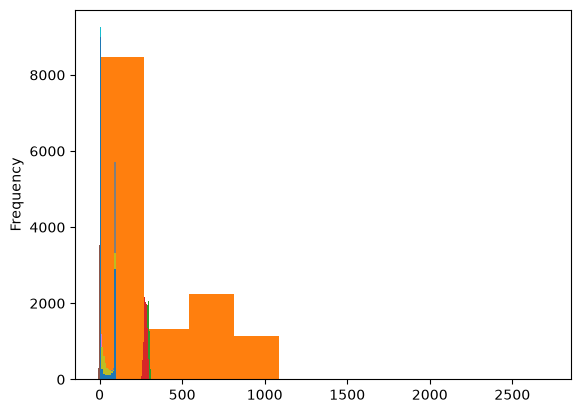

In [81]:
for val in feature_cols:
    forecast2022[val].plot(kind='hist')


| Variable | Plain English Name | Description | Typical Units |
| :--- | :--- | :--- | :--- |
| `dswrf` | **Downward Shortwave Solar Radiation** | Total solar radiation arriving at ground level (global horizontal irradiance). Key driver for solar PV output. | $\text{W/m}^2$ |
| `vbdsf` | **Direct Beam Solar Radiation** | Direct sunlight component hitting the surface without being scattered by clouds or haze. | $\text{W/m}^2$ |
| `tmp_2m` | **2-Meter Air Temperature** | Ambient air temperature measured at standard weather-station height (~6.5 ft above ground). | $\text{K}$ (Kelvin) |
| `dpt_2m` | **2-Meter Dew Point** | Moisture metric: the temperature air must cool to for condensation/humidity saturation. | $\text{K}$ (Kelvin) |
| `ugrd_10m` | **10-Meter East–West Wind** | Zonal wind component at standard anemometer height (+ means blowing toward East, - toward West). | $\text{m/s}$ |
| `vgrd_10m` | **10-Meter North–South Wind** | Meridional wind component (+ means blowing toward North, - toward South). | $\text{m/s}$ |
| `gust` | **Surface Wind Gust** | Peak instantaneous wind speed at ground level. | $\text{m/s}$ |
| `tcdc` | **Total Cloud Cover** | Percentage of the sky obstructed by clouds across the entire atmospheric column. | $\%$ ($0\text{--}100$) |
| `lcdc` | **Low-Level Cloud Cover** | Cloud fraction in the low atmospheric layer (typically surface to ~6,500 ft). | $\%$ ($0\text{--}100$) |
| `mcdc` | **Mid-Level Cloud Cover** | Cloud fraction in the middle layer (~6,500 to ~20,000 ft). | $\%$ ($0\text{--}100$) |
| `hcdc` | **High-Level Cloud Cover** | Cloud fraction in the high layer (typically cirrus clouds above ~20,000 ft). | $\%$ ($0\text{--}100$) |

## Weather Observations

In [35]:
import openmeteo_requests

import requests_cache
from retry_requests import retry


Open-Meteo has rate limits of 10,000 daily calls 5,000 per hour and 600 per minute. 
Using their browser API explorer, pulling all 11 hourly variables for the 4 centroids, for a full year was equivalent to ~114 Calls
Pulling the same data for just a single day was ~4.4 calls. So something doesn't scale linearly.
It shouldn't matter what those inner workings are, just that we avoid pulling data day by day. I'll likely do it a year at a time

In [36]:
STATION_POINTS = pd.DataFrame({
    "latitude": [42.3601, 42.2626, 41.7658, 44.8016],
    "longitude": [-71.0589, -71.8023, -72.6734, -68.7712],
    "stid": ["BOS", "ORH", "BDL", "BGR"],
})

In [ ]:
#code take directly from Open Meteo
def fetch_yearly_weather(start_year :int, end_year :int,points:pd.DataFrame) -> pd.DataFrame:
	""" Fetches hourly observed weather from Open-Meteo API for years specified. [inclusive,exclusive)
		points should be a dataframe with cols ["latitutde","longitude","stid"]
		"""

	##Temperature in Celsius, Windspeed in m/s


	cache_session = requests_cache.CachedSession('.cache', expire_after = -1)
	retry_session = retry(cache_session, retries = 5, backoff_factor = 0.2)
	openmeteo = openmeteo_requests.Client(session = retry_session)

	# Make sure all required weather variables are listed here
	# The order of variables in hourly or daily is important to assign them correctly below
	url = "https://archive-api.open-meteo.com/v1/archive"
	params = {
		"latitude": points["latitude"],
		"longitude": points["longitude"],
		"start_date": f"{start_year}-01-01",
		"end_date": f"{end_year -1}-12-31",
		"hourly": ["temperature_2m", "dew_point_2m", "cloud_cover", "cloud_cover_mid", "cloud_cover_high", "cloud_cover_low", "wind_speed_10m", 
					"wind_direction_10m", "wind_gusts_10m", "shortwave_radiation", "direct_radiation"],
		"wind_speed_unit": "ms",
	}
	responses = openmeteo.weather_api(url, params = params)

	return_df = []
	# Process 4 locations
	for i,response in enumerate(responses):
		print(f"\nCoordinates: {response.Latitude()}°N {response.Longitude()}°E")
		print(f"Elevation: {response.Elevation()} m asl")
		print(f"Timezone difference to GMT+0: {response.UtcOffsetSeconds()}s")
		
		# Process hourly data. The order of variables needs to be the same as requested.
		hourly = response.Hourly()
		hourly_temperature_2m = hourly.Variables(0).ValuesAsNumpy()
		hourly_dew_point_2m = hourly.Variables(1).ValuesAsNumpy()
		hourly_cloud_cover = hourly.Variables(2).ValuesAsNumpy()
		hourly_cloud_cover_mid = hourly.Variables(3).ValuesAsNumpy()
		hourly_cloud_cover_high = hourly.Variables(4).ValuesAsNumpy()
		hourly_cloud_cover_low = hourly.Variables(5).ValuesAsNumpy()
		hourly_wind_speed_10m = hourly.Variables(6).ValuesAsNumpy()
		hourly_wind_direction_10m = hourly.Variables(7).ValuesAsNumpy()
		hourly_wind_gusts_10m = hourly.Variables(8).ValuesAsNumpy()
		hourly_shortwave_radiation = hourly.Variables(9).ValuesAsNumpy()
		hourly_direct_radiation = hourly.Variables(10).ValuesAsNumpy()
		

		hourly_data = {
			"datetime_utc": pd.date_range(
				start = pd.to_datetime(hourly.Time(), unit = "s", utc = True),
				end =  pd.to_datetime(hourly.TimeEnd(), unit = "s", utc = True),
				freq = pd.Timedelta(seconds = hourly.Interval()),
				inclusive = "left"
			)
		}
		hourly_data["point_stid"] = points.iloc[i]["stid"]
		
		hourly_data["temperature_2m"] = hourly_temperature_2m
		hourly_data["dew_point_2m"] = hourly_dew_point_2m
		hourly_data["cloud_cover"] = hourly_cloud_cover
		hourly_data["cloud_cover_mid"] = hourly_cloud_cover_mid
		hourly_data["cloud_cover_high"] = hourly_cloud_cover_high
		hourly_data["cloud_cover_low"] = hourly_cloud_cover_low
		hourly_data["wind_speed_10m"] = hourly_wind_speed_10m
		hourly_data["wind_direction_10m"] = hourly_wind_direction_10m
		hourly_data["wind_gusts_10m"] = hourly_wind_gusts_10m
		hourly_data["shortwave_radiation"] = hourly_shortwave_radiation
		hourly_data["direct_radiation"] = hourly_direct_radiation
		
		hourly_dataframe = pd.DataFrame(data = hourly_data)

		return_df.append(hourly_dataframe)
	return_df = pd.concat(return_df,ignore_index=True)
	return return_df			
	

In [46]:
all_weather = wl.fetch_yearly_weather(2026 ,2027,STATION_POINTS)
all_weather.to_parquet("data/raw/weather_observed/weather_observations_2026.parquet", index=False)




Coordinates: 42.35500717163086°N -71.12905883789062°E
Elevation: 9.0 m asl
Timezone difference to GMT+0: 0s

Coordinates: 42.28470993041992°N -71.81552124023438°E
Elevation: 153.0 m asl
Timezone difference to GMT+0: 0s

Coordinates: 41.79261779785156°N -72.65219116210938°E
Elevation: 32.0 m asl
Timezone difference to GMT+0: 0s

Coordinates: 44.81546401977539°N -68.71713256835938°E
Elevation: 15.0 m asl
Timezone difference to GMT+0: 0s


In [61]:
all_weather.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 175296 entries, 0 to 175295
Data columns (total 13 columns):
 #   Column               Non-Null Count   Dtype              
---  ------               --------------   -----              
 0   date                 175296 non-null  datetime64[ns, UTC]
 1   point_stid           175296 non-null  object             
 2   temperature_2m       175296 non-null  float32            
 3   dew_point_2m         175296 non-null  float32            
 4   cloud_cover          175296 non-null  float32            
 5   cloud_cover_mid      175296 non-null  float32            
 6   cloud_cover_high     175296 non-null  float32            
 7   cloud_cover_low      175296 non-null  float32            
 8   wind_speed_10m       175296 non-null  float32            
 9   wind_direction_10m   175296 non-null  float32            
 10  wind_gusts_10m       175296 non-null  float32            
 11  shortwave_radiation  175296 non-null  float32            
 12  di

In [62]:
all_weather.describe()

,temperature_2m,dew_point_2m,cloud_cover,cloud_cover_mid,cloud_cover_high,cloud_cover_low,wind_speed_10m,wind_direction_10m,wind_gusts_10m,shortwave_radiation,direct_radiation
count,175296.000000,175296.000000,175296.000000,175296.000000,175296.000000,175296.000000,175296.000000,175296.000000,175296.000000,175296.000000,175296.000000
mean,10.190439,4.694058,58.826546,29.960346,40.607544,25.748922,3.246039,211.577316,7.126917,164.039963,106.377647
std,10.381819,10.644620,42.870956,39.686783,44.521347,38.883430,1.637897,98.848618,3.491297,240.239487,188.495667
min,-29.750000,-38.750000,0.000000,0.000000,0.000000,0.000000,0.000000,0.473501,0.200000,0.000000,0.000000
25%,2.000000,-3.152500,7.000000,0.000000,0.000000,0.000000,2.080865,157.619827,4.500000,0.000000,0.000000
50%,10.550000,5.500000,79.000000,4.000000,12.000000,1.000000,3.022003,227.167923,6.600000,7.000000,0.000000
75%,18.500000,13.400000,100.000000,64.000000,98.000000,42.000000,4.183898,291.370697,9.200000,285.000000,135.000000
max,38.847500,26.147499,100.000000,100.000000,100.000000,100.000000,15.005333,360.000000,29.000000,983.000000,880.000000


In [63]:
all_weather.groupby("point_stid")[["temperature_2m", "shortwave_radiation", "wind_speed_10m"]].mean()


,temperature_2m,shortwave_radiation,wind_speed_10m
point_stid,,,
BDL,11.318400,166.346664,2.801007
BGR,8.245969,156.385468,3.138861
BOS,11.112378,167.170410,3.605673
ORH,10.085007,166.257263,3.438616


In [ ]:
all_weather.to_parquet("data/raw/weather_observed/weather_observations_2021_2025.parquet", index=False)